In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error

import warnings

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


In [3]:
input_dir = Path("../../data/raw/PeMS")
output_dir = Path("../../data/processed/PeMS")
output_dir.mkdir(parents=True, exist_ok=True)

files = {
    "716714": {
        "speed": input_dir / "VDS 716714(2019.10.2_I405-N_Abs_PM_52.3)_flow_speed.txt",
        "occupancy": input_dir
        / "VDS 716714(2019.10.2_I405-N_Abs_PM_52.3)_flow_occupancy.txt",
        "lanes": 5,
        "postmile": 52.3,
    },
    "759427": {
        "speed": input_dir / "VDS 759427(2019.10.2_I405-N_Abs_PM_45.1)_flow_speed.txt",
        "occupancy": input_dir
        / "VDS 759427(2019.10.2_I405-N_Abs_PM_45.1)_flow_occupancy.txt",
        "lanes": 4,
        "postmile": 45.1,
    },
}

In [4]:
def load_pems_data(filepath):

    df = pd.read_csv(filepath, sep="\t")

    # Remove possible leading/trailing spaces
    df.columns = df.columns.str.strip()

    # Convert time column
    df["5 Minutes"] = pd.to_datetime(df["5 Minutes"], format="%m/%d/%Y %H:%M")

    return df


data = {}

for detector, info in files.items():
    df_speed = load_pems_data(info["speed"])
    df_occ = load_pems_data(info["occupancy"])

    data[detector] = {"speed": df_speed, "occupancy": df_occ}

    print(f"Detector {detector}")
    print("Speed data:", df_speed.shape)
    print("Occupancy data:", df_occ.shape)
    print()


Detector 716714
Speed data: (288, 15)
Occupancy data: (288, 15)

Detector 759427
Speed data: (288, 13)
Occupancy data: (288, 13)



In [5]:
processed = {}

for detector, info in files.items():
    df_speed = data[detector]["speed"].copy()
    df_occ = data[detector]["occupancy"].copy()

    # Extract total flow and speed
    speed_part = df_speed[
        ["5 Minutes", "Flow (Veh/5 Minutes)", "Speed (mph)", "% Observed"]
    ].copy()

    # Extract total occupancy
    occ_part = df_occ[["5 Minutes", "Occupancy (%)"]].copy()

    # Merge by timestamp
    df = pd.merge(speed_part, occ_part, on="5 Minutes", how="inner")

    # Rename columns
    df = df.rename(
        columns={
            "5 Minutes": "time",
            "Flow (Veh/5 Minutes)": "flow_5min",
            "Speed (mph)": "speed_mph",
            "Occupancy (%)": "occupancy",
        }
    )

    # Convert units
    df["flow"] = df["flow_5min"] * 12

    df["speed_kmh"] = df["speed_mph"] * 1.60934

    df["speed_mps"] = df["speed_mph"] * 0.44704

    # Calculate approximate density
    df["density"] = df["flow"] / df["speed_kmh"]

    # Per-lane quantities
    df["flow_per_lane"] = df["flow"] / info["lanes"]

    df["density_per_lane"] = df["density"] / info["lanes"]

    # Store
    processed[detector] = df

    print(f"Detector {detector}")
    print(df.head())
    print()


Detector 716714
                 time  flow_5min  speed_mph  % Observed  occupancy    flow  \
0 2019-10-02 00:00:00      246.0       72.8       100.0        4.0  2952.0   
1 2019-10-02 00:05:00      189.0       74.0       100.0        3.1  2268.0   
2 2019-10-02 00:10:00      222.0       72.2       100.0        3.8  2664.0   
3 2019-10-02 00:15:00      245.0       74.3       100.0        3.8  2940.0   
4 2019-10-02 00:20:00      186.0       72.2       100.0        3.3  2232.0   

    speed_kmh  speed_mps    density  flow_per_lane  density_per_lane  
0  117.159952  32.544512  25.196323          590.4          5.039265  
1  119.091160  33.080960  19.044235          453.6          3.808847  
2  116.194348  32.276288  22.927105          532.8          4.585421  
3  119.573962  33.215072  24.587293          588.0          4.917459  
4  116.194348  32.276288  19.209196          446.4          3.841839  

Detector 759427
                 time  flow_5min  speed_mph  % Observed  occupancy    fl

In [6]:
for detector, df in processed.items():
    print("=" * 55)
    print(f"Detector: {detector}")
    print("=" * 55)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nInvalid speed:")
    print((df["speed_kmh"] <= 0).sum())

    print("\nInvalid flow:")
    print((df["flow"] < 0).sum())

    print("\nObserved percentage:")
    print(df["% Observed"].describe())

    print("\nDensity statistics:")
    print(df["density_per_lane"].describe())


Detector: 716714

Missing values:
time                0
flow_5min           0
speed_mph           0
% Observed          0
occupancy           0
flow                0
speed_kmh           0
speed_mps           0
density             0
flow_per_lane       0
density_per_lane    0
dtype: int64

Invalid speed:
0

Invalid flow:
0

Observed percentage:
count    288.000000
mean      99.652778
std        5.892557
min        0.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: % Observed, dtype: float64

Density statistics:
count    288.000000
mean      25.426044
std       16.970687
min        1.311493
25%        7.744523
50%       32.907169
75%       39.063480
max       57.981533
Name: density_per_lane, dtype: float64
Detector: 759427

Missing values:
time                0
flow_5min           0
speed_mph           0
% Observed          0
occupancy           0
flow                0
speed_kmh           0
speed_mps           0
density             0
flow_per_

In [7]:
cleaned = {}

for detector, df in processed.items():
    valid = (
        df["flow"].notna()
        & df["speed_kmh"].notna()
        & df["occupancy"].notna()
        & (df["flow"] >= 0)
        & (df["speed_kmh"] > 0)
        & (df["% Observed"] == 100)
    )

    df_clean = df.loc[valid].copy()

    cleaned[detector] = df_clean

    print(f"Detector {detector}: {len(df)} -> {len(df_clean)} observations")


Detector 716714: 288 -> 287 observations
Detector 759427: 288 -> 287 observations


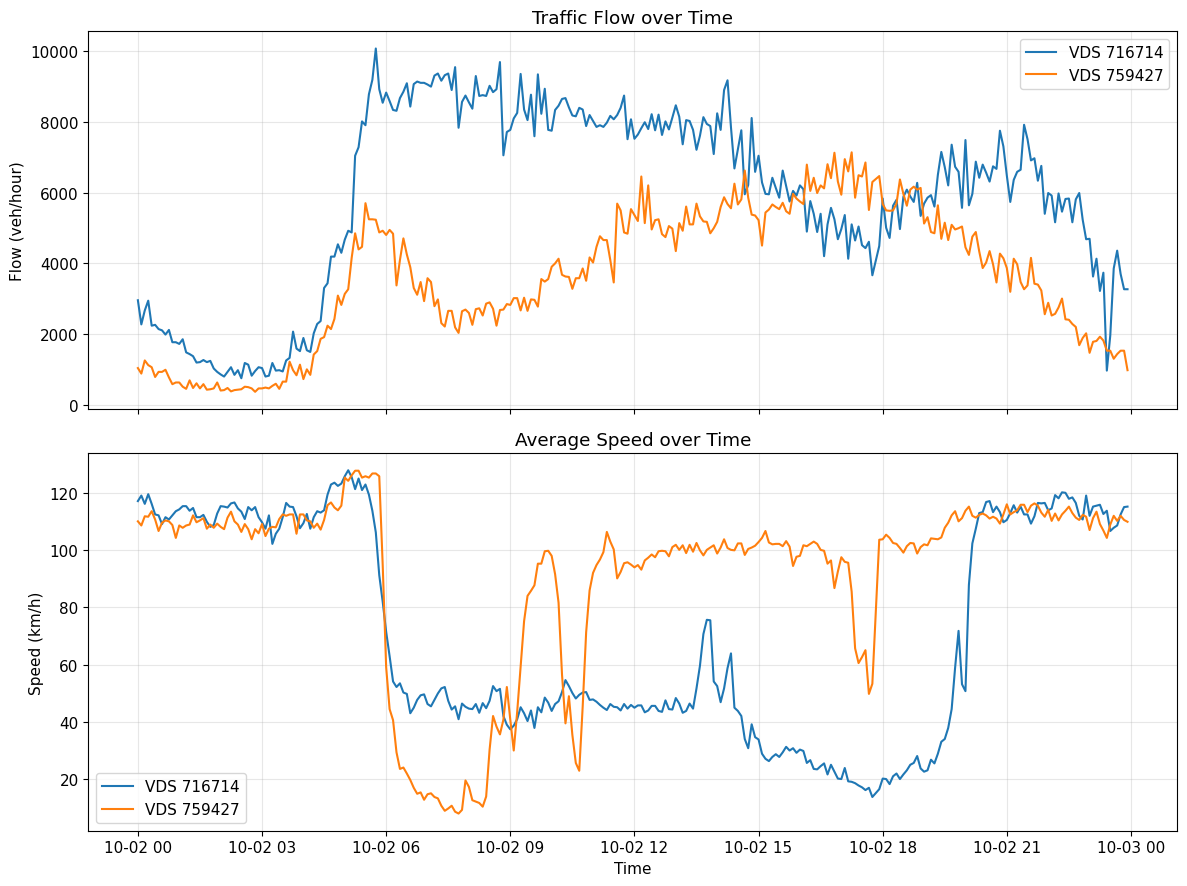

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for detector, df in cleaned.items():
    axes[0].plot(df["time"], df["flow"], label=f"VDS {detector}")

    axes[1].plot(df["time"], df["speed_kmh"], label=f"VDS {detector}")

axes[0].set_ylabel("Flow (veh/hour)")
axes[0].set_title("Traffic Flow over Time")
axes[0].legend()

axes[1].set_ylabel("Speed (km/h)")
axes[1].set_xlabel("Time")
axes[1].set_title("Average Speed over Time")
axes[1].legend()

plt.tight_layout()
plt.show()


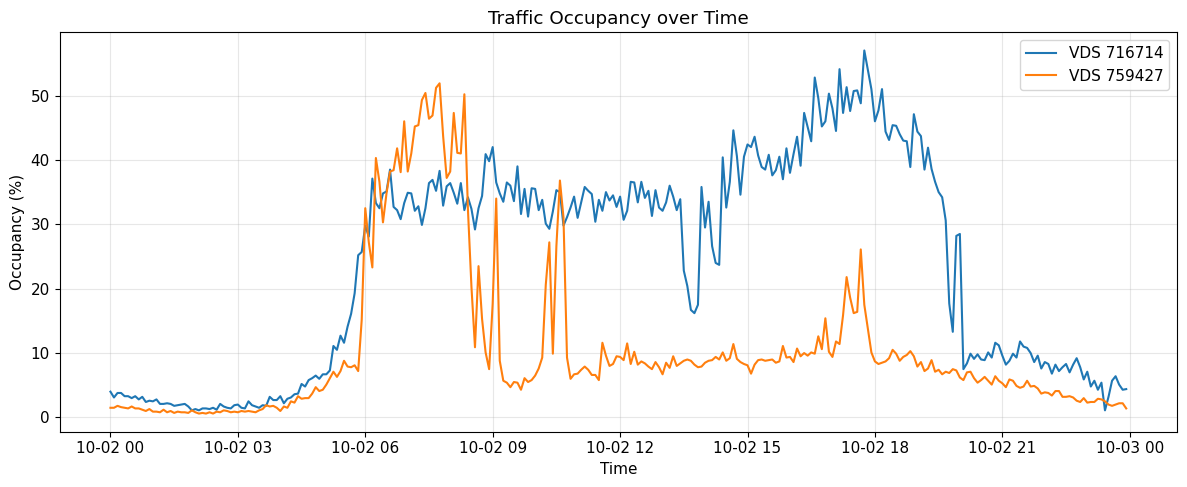

In [9]:
plt.figure(figsize=(12, 5))

for detector, df in cleaned.items():
    plt.plot(df["time"], df["occupancy"], label=f"VDS {detector}")

plt.xlabel("Time")
plt.ylabel("Occupancy (%)")
plt.title("Traffic Occupancy over Time")
plt.legend()

plt.tight_layout()
plt.show()


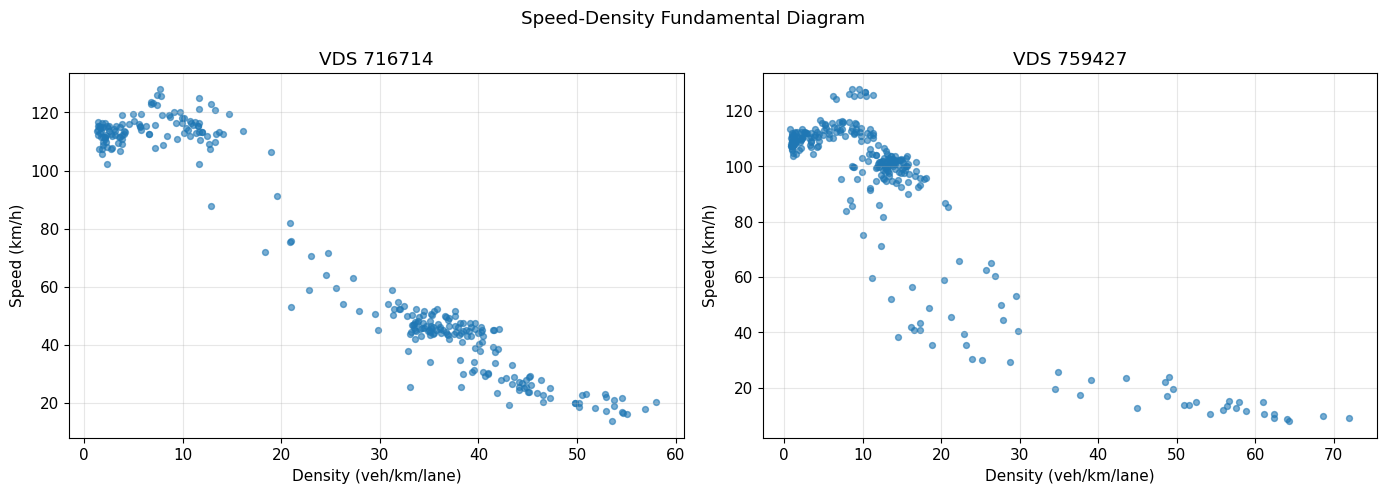

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (detector, df) in zip(axes, cleaned.items()):
    ax.scatter(df["density_per_lane"], df["speed_kmh"], s=18, alpha=0.6)

    ax.set_xlabel("Density (veh/km/lane)")
    ax.set_ylabel("Speed (km/h)")
    ax.set_title(f"VDS {detector}")

plt.suptitle("Speed-Density Fundamental Diagram")

plt.tight_layout()
plt.show()


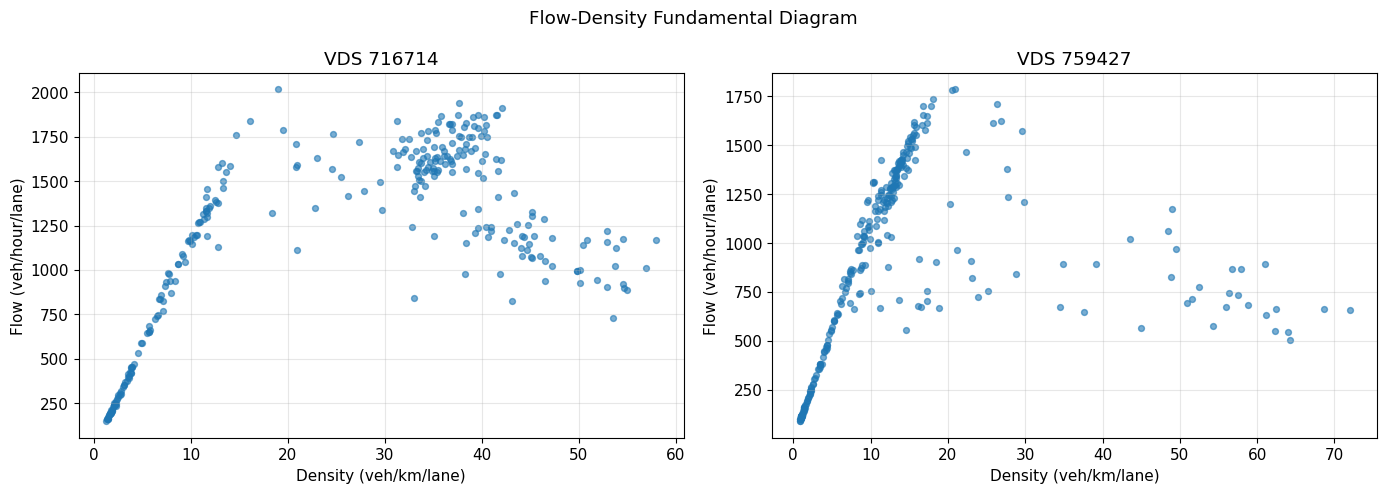

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (detector, df) in zip(axes, cleaned.items()):
    ax.scatter(df["density_per_lane"], df["flow_per_lane"], s=18, alpha=0.6)

    ax.set_xlabel("Density (veh/km/lane)")
    ax.set_ylabel("Flow (veh/hour/lane)")
    ax.set_title(f"VDS {detector}")

plt.suptitle("Flow-Density Fundamental Diagram")

plt.tight_layout()
plt.show()


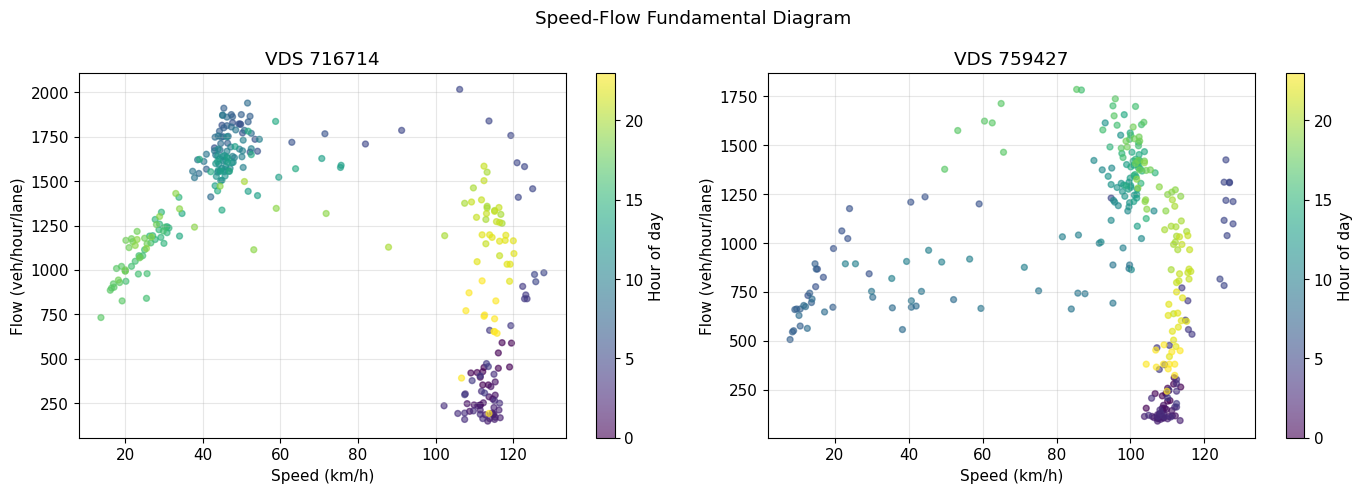

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (detector, df) in zip(axes, cleaned.items()):
    scatter = ax.scatter(
        df["speed_kmh"],
        df["flow_per_lane"],
        c=df["time"].dt.hour,
        cmap="viridis",
        s=18,
        alpha=0.6,
    )

    ax.set_xlabel("Speed (km/h)")
    ax.set_ylabel("Flow (veh/hour/lane)")
    ax.set_title(f"VDS {detector}")

    plt.colorbar(scatter, ax=ax, label="Hour of day")

plt.suptitle("Speed-Flow Fundamental Diagram")

plt.tight_layout()
plt.show()


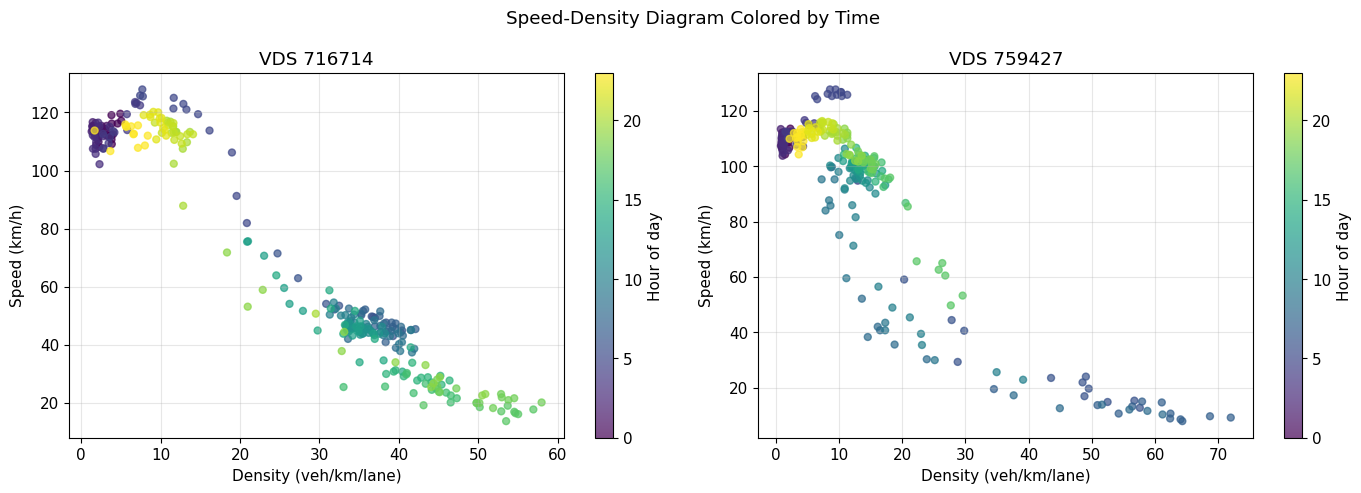

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (detector, df) in zip(axes, cleaned.items()):
    scatter = ax.scatter(
        df["density_per_lane"],
        df["speed_kmh"],
        c=df["time"].dt.hour,
        cmap="viridis",
        s=25,
        alpha=0.7,
    )

    ax.set_xlabel("Density (veh/km/lane)")
    ax.set_ylabel("Speed (km/h)")
    ax.set_title(f"VDS {detector}")

    plt.colorbar(scatter, ax=ax, label="Hour of day")

plt.suptitle("Speed-Density Diagram Colored by Time")

plt.tight_layout()
plt.show()

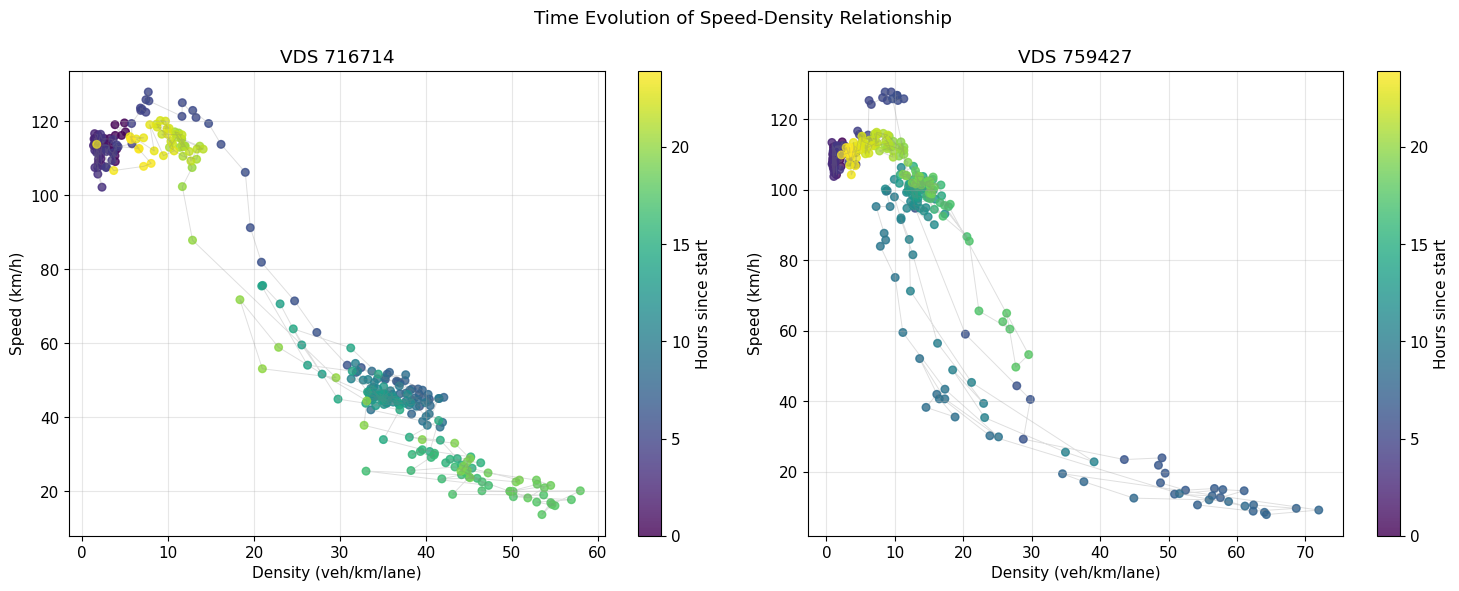

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (detector, df) in zip(axes, cleaned.items()):
    df_plot = df.sort_values("time").copy()

    time_hours = (df_plot["time"] - df_plot["time"].min()).dt.total_seconds() / 3600

    # Scatter plot
    scatter = ax.scatter(
        df_plot["density_per_lane"],
        df_plot["speed_kmh"],
        c=time_hours,
        cmap="viridis",
        s=30,
        alpha=0.8,
    )

    # Connect consecutive observations
    ax.plot(
        df_plot["density_per_lane"],
        df_plot["speed_kmh"],
        color="grey",
        alpha=0.25,
        linewidth=0.7,
    )

    ax.set_xlabel("Density (veh/km/lane)")
    ax.set_ylabel("Speed (km/h)")
    ax.set_title(f"VDS {detector}")

    plt.colorbar(scatter, ax=ax, label="Hours since start")

plt.suptitle("Time Evolution of Speed-Density Relationship")

plt.tight_layout()
plt.show()


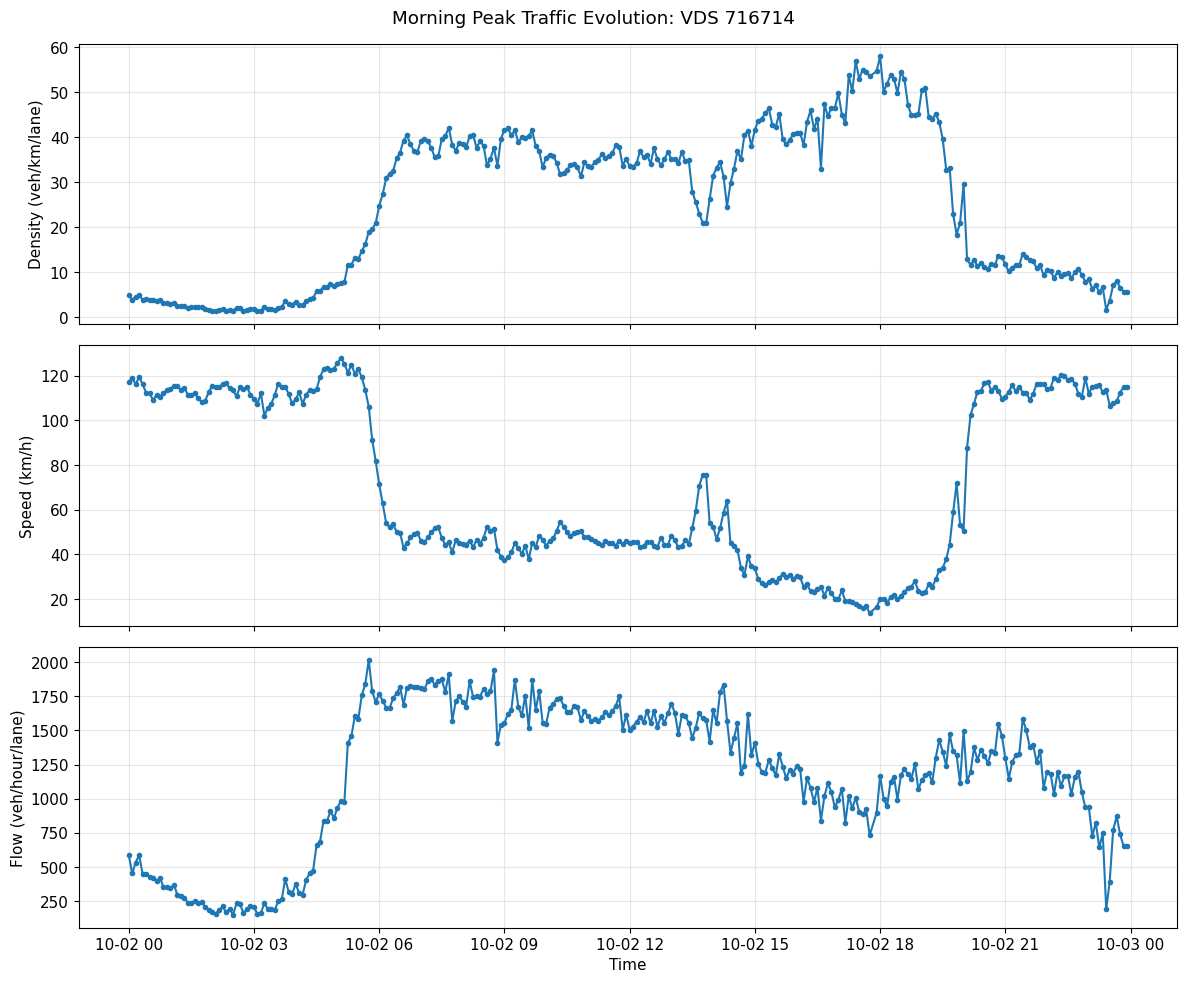

In [ ]:
detector = "716714"

df = cleaned[detector].copy()

df["hour"] = df["time"].dt.hour + df["time"].dt.minute / 60

# # Example morning period
# morning = df[(df["hour"] >= 4) & (df["hour"] <= 10)].copy()

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

variables = [
    ("density_per_lane", "Density (veh/km/lane)"),
    ("speed_kmh", "Speed (km/h)"),
    ("flow_per_lane", "Flow (veh/hour/lane)"),
]

for ax, (column, ylabel) in zip(axes, variables):
    ax.plot(
        # morning["time"],
        # morning[column],
        df["time"],
        df[column],
        marker="o",
        markersize=3,
    )

    ax.set_ylabel(ylabel)

axes[-1].set_xlabel("Time")

plt.suptitle("Morning Peak Traffic Evolution: VDS 716714")

plt.tight_layout()
plt.show()


Formation observations: 16
Dissipation observations: 11


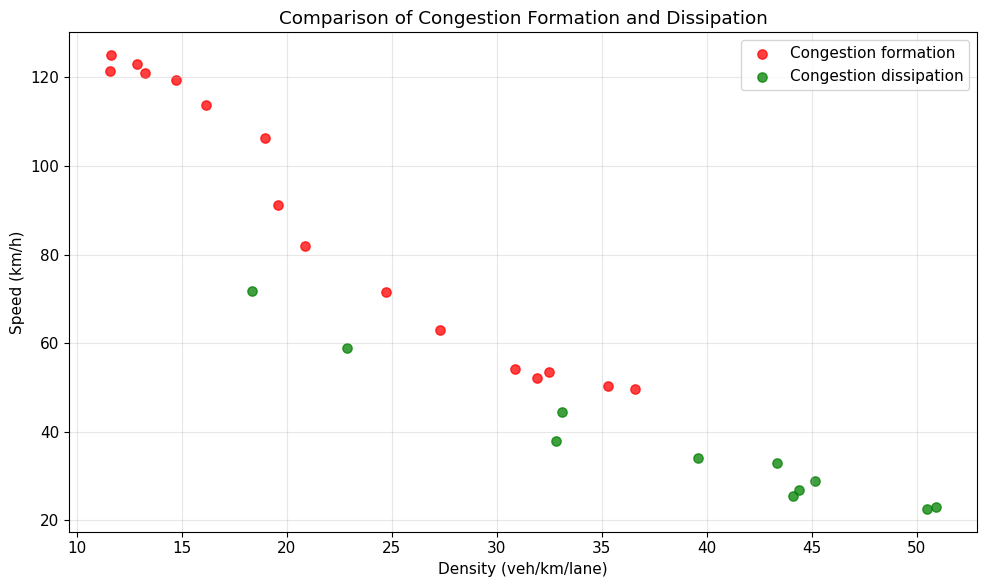

In [31]:
detector = "716714"

df = cleaned[detector].copy()

df = df.sort_values("time").reset_index(drop=True)

# Define traffic phases
formation_start = pd.Timestamp("2019-10-02 05:15")
formation_end = pd.Timestamp("2019-10-02 06:30")

# dissipation_start = pd.Timestamp("2019-10-02 18:45")
dissipation_start = pd.Timestamp("2019-10-02 19:00")
# dissipation_end = pd.Timestamp("2019-10-02 20:00")
dissipation_end = pd.Timestamp("2019-10-02 19:50")


formation = df[(df["time"] >= formation_start) & (df["time"] <= formation_end)].copy()

dissipation = df[
    (df["time"] >= dissipation_start) & (df["time"] <= dissipation_end)
].copy()

print("Formation observations:", len(formation))
print("Dissipation observations:", len(dissipation))

plt.figure(figsize=(10, 6))

plt.scatter(
    formation["density_per_lane"],
    formation["speed_kmh"],
    color="red",
    label="Congestion formation",
    alpha=0.75,
    s=45,
)

plt.scatter(
    dissipation["density_per_lane"],
    dissipation["speed_kmh"],
    color="green",
    label="Congestion dissipation",
    alpha=0.75,
    s=45,
)

plt.xlabel("Density (veh/km/lane)")
plt.ylabel("Speed (km/h)")

plt.title("Comparison of Congestion Formation and Dissipation")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Formation speed,Dissipation speed,Speed difference
density_bin,,,
"[12, 15)",121.022368,NaN,NaN
"[15, 18)",113.780338,NaN,NaN
"[18, 21)",91.249578,62.442392,-28.807186
"[21, 24)",NaN,58.901844,NaN
"[24, 27)",71.454696,NaN,NaN
"[27, 30)",62.925194,50.694210,-12.230984
"[30, 33)",53.430088,37.819490,-15.610598
"[33, 36)",50.211408,44.417784,-5.793624
"[36, 39)",49.728606,NaN,NaN


Common density intervals:


,Formation speed,Dissipation speed,Speed difference
density_bin,,,
"[18, 21)",91.25,62.44,-28.81
"[27, 30)",62.93,50.69,-12.23
"[30, 33)",53.43,37.82,-15.61
"[33, 36)",50.21,44.42,-5.79


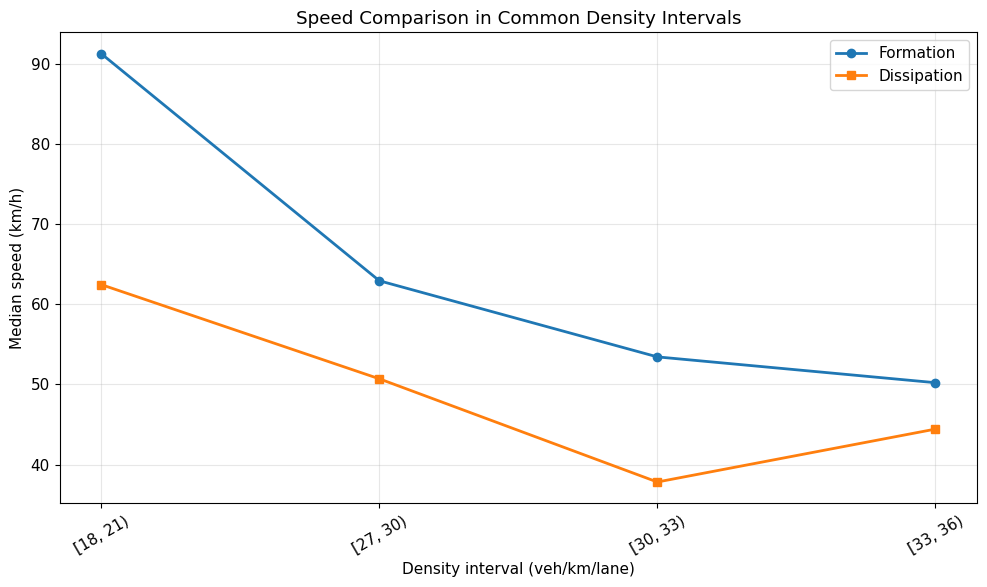

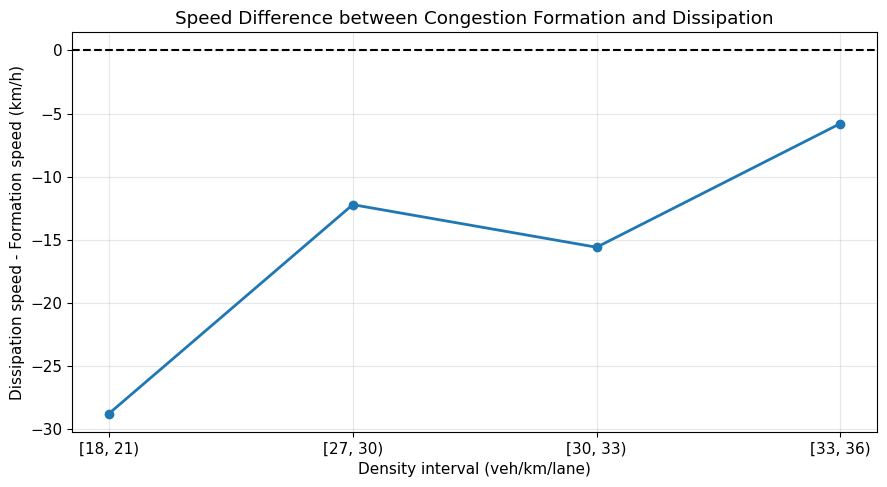

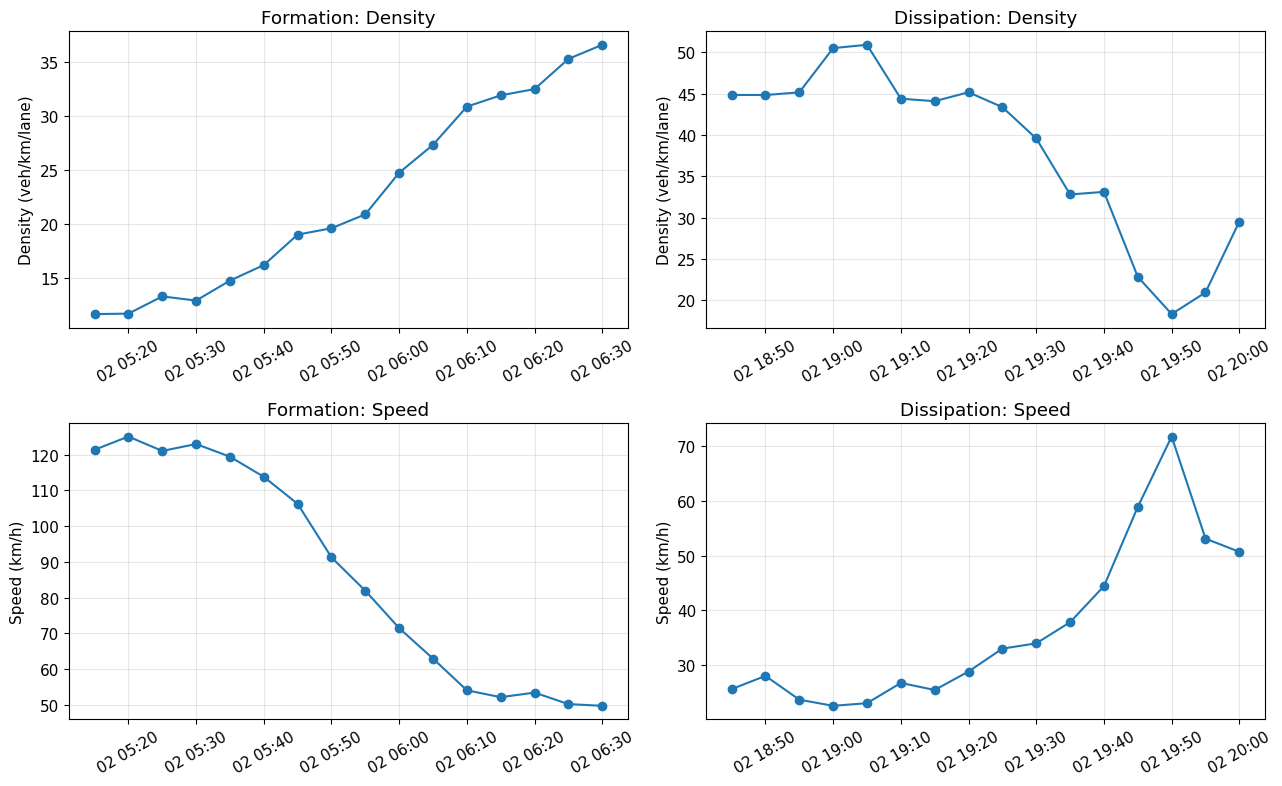

In [ ]:
# ==========================================
# Calculate median speed in each density bin
# ==========================================

bins = np.arange(12, 43, 3)

formation = formation.copy()
dissipation = dissipation.copy()

formation["density_bin"] = pd.cut(formation["density_per_lane"], bins=bins, right=False)

dissipation["density_bin"] = pd.cut(
    dissipation["density_per_lane"], bins=bins, right=False
)

formation_speed = formation.groupby("density_bin", observed=False)["speed_kmh"].median()

dissipation_speed = dissipation.groupby("density_bin", observed=False)[
    "speed_kmh"
].median()

# Create comparison DataFrame
comparison = pd.DataFrame(
    {"Formation speed": formation_speed, "Dissipation speed": dissipation_speed}
)

comparison["Speed difference"] = (
    comparison["Dissipation speed"] - comparison["Formation speed"]
)

display(comparison)

# Keep only density bins observed in both phases
common = comparison.dropna(subset=["Formation speed", "Dissipation speed"]).copy()

common["Speed difference"] = common["Dissipation speed"] - common["Formation speed"]

print("Common density intervals:")
display(common.round(2))

# Plot only common intervals
x = np.arange(len(common))

plt.figure(figsize=(10, 6))

plt.plot(x, common["Formation speed"], marker="o", linewidth=2, label="Formation")

plt.plot(x, common["Dissipation speed"], marker="s", linewidth=2, label="Dissipation")

plt.xticks(x, common.index.astype(str), rotation=30)

plt.xlabel("Density interval (veh/km/lane)")
plt.ylabel("Median speed (km/h)")

plt.title("Speed Comparison in Common Density Intervals")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

plt.plot(common.index.astype(str), common["Speed difference"], marker="o", linewidth=2)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Density interval (veh/km/lane)")
plt.ylabel("Dissipation speed - Formation speed (km/h)")

plt.title("Speed Difference between Congestion Formation and Dissipation")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, group, label in [
    (axes[0, 0], formation, "Formation"),
    (axes[0, 1], dissipation, "Dissipation"),
]:
    ax.plot(group["time"], group["density_per_lane"], marker="o")

    ax.set_title(f"{label}: Density")
    ax.set_ylabel("Density (veh/km/lane)")
    ax.tick_params(axis="x", rotation=30)

for ax, group, label in [
    (axes[1, 0], formation, "Formation"),
    (axes[1, 1], dissipation, "Dissipation"),
]:
    ax.plot(group["time"], group["speed_kmh"], marker="o")

    ax.set_title(f"{label}: Speed")
    ax.set_ylabel("Speed (km/h)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


Formation observations: 16
Dissipation observations: 11


,Formation speed,Dissipation speed,Speed difference
density_bin,,,
"[18, 21)",91.25,71.78,-19.47
"[30, 33)",53.43,37.82,-15.61
"[33, 36)",50.21,44.42,-5.79


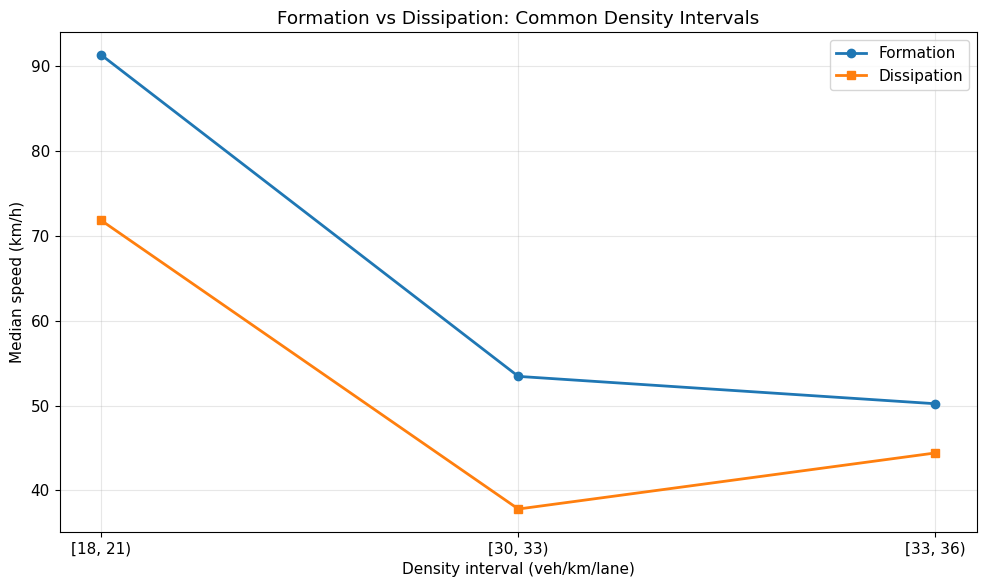

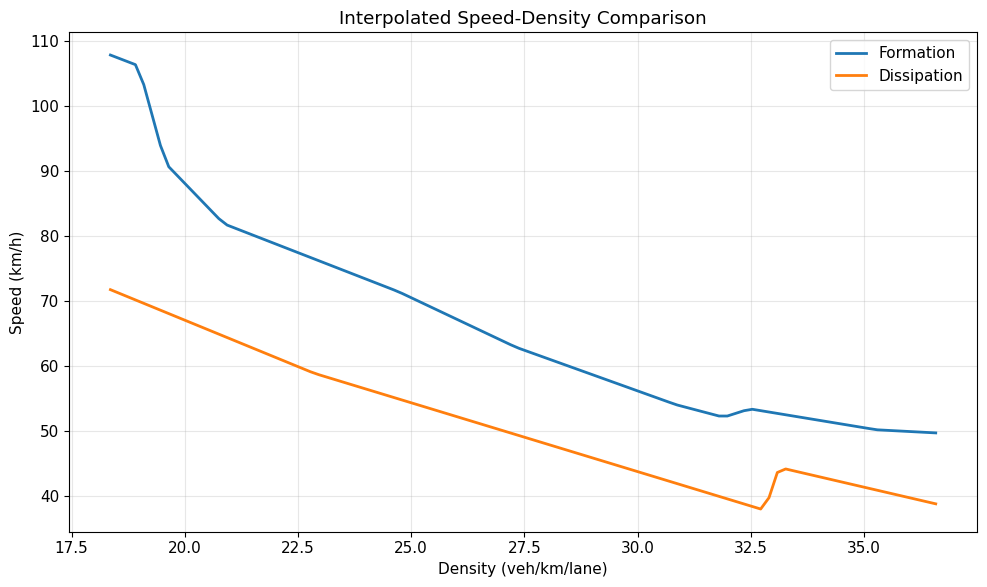

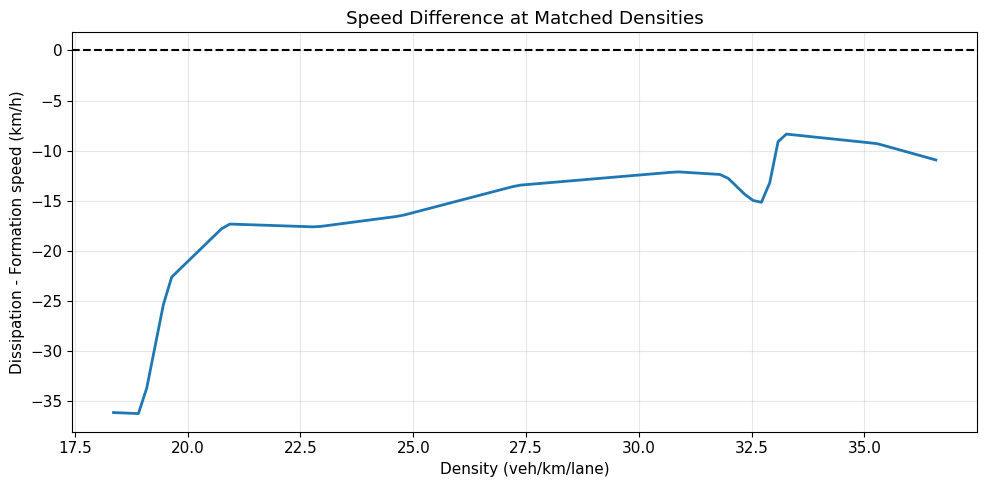

In [ ]:
detector = "716714"

df = cleaned[detector].copy()

df = df.sort_values("time").reset_index(drop=True)

# Morning congestion formation
formation_start = pd.Timestamp("2019-10-02 05:15")
formation_end = pd.Timestamp("2019-10-02 06:30")

# Evening congestion dissipation
dissipation_start = pd.Timestamp("2019-10-02 19:00")
dissipation_end = pd.Timestamp("2019-10-02 19:50")

formation = df[(df["time"] >= formation_start) & (df["time"] <= formation_end)].copy()

dissipation = df[
    (df["time"] >= dissipation_start) & (df["time"] <= dissipation_end)
].copy()

print("Formation observations:", len(formation))
print("Dissipation observations:", len(dissipation))

bins = np.arange(12, 55, 3)

formation["density_bin"] = pd.cut(formation["density_per_lane"], bins=bins, right=False)

dissipation["density_bin"] = pd.cut(
    dissipation["density_per_lane"], bins=bins, right=False
)

formation_speed = formation.groupby("density_bin", observed=False)["speed_kmh"].median()

dissipation_speed = dissipation.groupby("density_bin", observed=False)[
    "speed_kmh"
].median()

comparison = pd.DataFrame(
    {"Formation speed": formation_speed, "Dissipation speed": dissipation_speed}
)

comparison["Speed difference"] = (
    comparison["Dissipation speed"] - comparison["Formation speed"]
)

common = comparison.dropna(subset=["Formation speed", "Dissipation speed"]).copy()

display(common.round(2))

plt.figure(figsize=(10, 6))

plt.plot(
    common.index.astype(str),
    common["Formation speed"],
    marker="o",
    linewidth=2,
    label="Formation",
)

plt.plot(
    common.index.astype(str),
    common["Dissipation speed"],
    marker="s",
    linewidth=2,
    label="Dissipation",
)

plt.xlabel("Density interval (veh/km/lane)")
plt.ylabel("Median speed (km/h)")

plt.title("Formation vs Dissipation: Common Density Intervals")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Sort both datasets by density
formation_sorted = formation.sort_values("density_per_lane")

dissipation_sorted = dissipation.sort_values("density_per_lane")

k_f = formation_sorted["density_per_lane"].to_numpy()
v_f = formation_sorted["speed_kmh"].to_numpy()

k_d = dissipation_sorted["density_per_lane"].to_numpy()
v_d = dissipation_sorted["speed_kmh"].to_numpy()

# Common density range
k_min = max(k_f.min(), k_d.min())
k_max = min(k_f.max(), k_d.max())

k_common = np.linspace(k_min, k_max, 100)

# Interpolate speed at the same density
v_f_interp = np.interp(k_common, k_f, v_f)

v_d_interp = np.interp(k_common, k_d, v_d)

# Speed difference
delta_v = v_d_interp - v_f_interp

plt.figure(figsize=(10, 6))

plt.plot(k_common, v_f_interp, label="Formation", linewidth=2)

plt.plot(k_common, v_d_interp, label="Dissipation", linewidth=2)

plt.xlabel("Density (veh/km/lane)")
plt.ylabel("Speed (km/h)")

plt.title("Interpolated Speed-Density Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Plot speed difference
plt.figure(figsize=(10, 5))

plt.plot(k_common, delta_v, linewidth=2)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Density (veh/km/lane)")
plt.ylabel("Dissipation - Formation speed (km/h)")

plt.title("Speed Difference at Matched Densities")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
def fit_greenshields_linear(df):

    k = df["density_per_lane"].to_numpy()
    v = df["speed_kmh"].to_numpy()

    # Linear regression:
    # v = beta_0 + beta_1 * k

    beta_1, beta_0 = np.polyfit(k, v, 1)

    # Recover Greenshields parameters
    vf = beta_0

    kj = -beta_0 / beta_1

    # Critical point
    kc = kj / 2

    vc = vf / 2

    qmax = vf * kj / 4

    # Model predictions
    v_pred = beta_0 + beta_1 * k

    # Goodness of fit
    r2 = r2_score(v, v_pred)

    rmse = np.sqrt(mean_squared_error(v, v_pred))

    return {
        "vf": vf,
        "kj": kj,
        "kc": kc,
        "vc": vc,
        "qmax": qmax,
        "beta_0": beta_0,
        "beta_1": beta_1,
        "r2": r2,
        "rmse": rmse,
    }


In [20]:
def greenshields_model(k, vf, kj):

    return vf * (1 - k / kj)


def fit_greenshields_nonlinear(df):

    k = df["density_per_lane"].to_numpy()
    v = df["speed_kmh"].to_numpy()

    # Initial guesses
    vf_initial = np.percentile(v, 95)

    kj_initial = max(2 * np.max(k), 1.0)

    # Nonlinear least squares
    params, covariance = curve_fit(
        greenshields_model,
        k,
        v,
        p0=[vf_initial, kj_initial],
        bounds=([0.01, np.max(k) + 1e-6], [200, 1000]),
        maxfev=20000,
    )

    vf, kj = params

    kc = kj / 2
    vc = vf / 2
    qmax = vf * kj / 4

    v_pred = greenshields_model(k, vf, kj)

    r2 = r2_score(v, v_pred)

    rmse = np.sqrt(mean_squared_error(v, v_pred))

    return {
        "vf": vf,
        "kj": kj,
        "kc": kc,
        "vc": vc,
        "qmax": qmax,
        "r2": r2,
        "rmse": rmse,
        "covariance": covariance,
    }


nonlinear_results = {}

for detector, df in cleaned.items():
    nonlinear_results[detector] = fit_greenshields_nonlinear(df)

    print(detector, nonlinear_results[detector])


716714 {'vf': 125.34679232685772, 'kj': 58.23723141397666, 'kc': 29.11861570698833, 'vc': 62.67339616342886, 'qmax': 1824.9625379347217, 'r2': 0.9392251043023587, 'rmse': 9.29153664453363, 'covariance': array([[ 0.98274793, -0.26693328],
       [-0.26693328,  0.30985967]])}
759427 {'vf': 115.86571607115165, 'kj': 71.9484231383987, 'kc': 35.97421156919935, 'vc': 57.932858035575826, 'qmax': 2084.0888917801954, 'r2': 0.7730156210621638, 'rmse': 14.984928636755647, 'covariance': array([[ 1.54116831, -1.39889181],
       [-1.39889181,  5.03654622]])}


In [21]:
results = {}

for detector, df in cleaned.items():
    result = fit_greenshields_linear(df)

    results[detector] = result

    print("=" * 55)
    print(f"Greenshields Model: VDS {detector}")
    print("=" * 55)

    print(f"Free-flow speed: {result['vf']:.4f} km/h")

    print(f"Jam density: {result['kj']:.4f} veh/km/lane")

    print(f"Critical density: {result['kc']:.4f} veh/km/lane")

    print(f"Critical speed: {result['vc']:.4f} km/h")

    print(f"Maximum flow: {result['qmax']:.4f} veh/hour/lane")

    print(f"R-squared: {result['r2']:.4f}")

    print(f"RMSE: {result['rmse']:.4f} km/h")

    print()


Greenshields Model: VDS 716714
Free-flow speed: 125.3468 km/h
Jam density: 58.2372 veh/km/lane
Critical density: 29.1186 veh/km/lane
Critical speed: 62.6734 km/h
Maximum flow: 1824.9625 veh/hour/lane
R-squared: 0.9392
RMSE: 9.2915 km/h

Greenshields Model: VDS 759427
Free-flow speed: 119.1370 km/h
Jam density: 62.0670 veh/km/lane
Critical density: 31.0335 veh/km/lane
Critical speed: 59.5685 km/h
Maximum flow: 1848.6194 veh/hour/lane
R-squared: 0.7950
RMSE: 14.2424 km/h



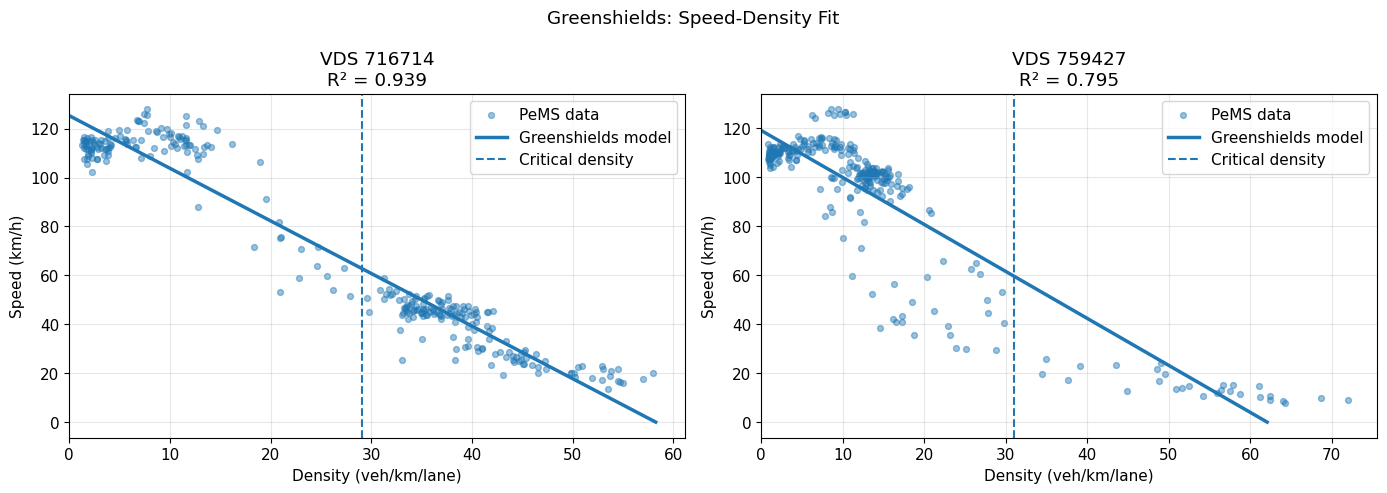

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (detector, df) in zip(axes, cleaned.items()):
    result = results[detector]

    k = df["density_per_lane"].to_numpy()
    v = df["speed_kmh"].to_numpy()

    # Density range
    k_fit = np.linspace(0, result["kj"], 300)

    # Theoretical Greenshields curve
    v_fit = greenshields_model(k_fit, result["vf"], result["kj"])

    # Experimental data
    ax.scatter(k, v, s=18, alpha=0.45, label="PeMS data")

    # Fitted curve
    ax.plot(k_fit, v_fit, linewidth=2.5, label="Greenshields model")

    # Critical density
    ax.axvline(result["kc"], linestyle="--", label="Critical density")

    ax.set_xlim(left=0)

    ax.set_xlabel("Density (veh/km/lane)")
    ax.set_ylabel("Speed (km/h)")

    ax.set_title(f"VDS {detector}\nR² = {result['r2']:.3f}")

    ax.legend()

plt.suptitle("Greenshields: Speed-Density Fit")

plt.tight_layout()
plt.show()


In [23]:
capacity_comparison = []

for detector, df in cleaned.items():
    result = results[detector]

    # Maximum observed flow
    idx = df["flow_per_lane"].idxmax()

    empirical_qmax = df.loc[idx, "flow_per_lane"]

    empirical_k_at_qmax = df.loc[idx, "density_per_lane"]

    capacity_comparison.append(
        {
            "Detector": detector,
            "Theoretical critical density": result["kc"],
            "Empirical density at max flow": empirical_k_at_qmax,
            "Theoretical capacity": result["qmax"],
            "Empirical maximum flow": empirical_qmax,
            "R2": result["r2"],
            "RMSE": result["rmse"],
        }
    )


capacity_df = pd.DataFrame(capacity_comparison)

display(capacity_df.round(3))


,Detector,Theoretical critical density,Empirical density at max flow,Theoretical capacity,Empirical maximum flow,R2,RMSE
0,716714,29.119,18.980,1824.963,2016.0,0.939,9.292
1,759427,31.033,20.888,1848.619,1785.0,0.795,14.242


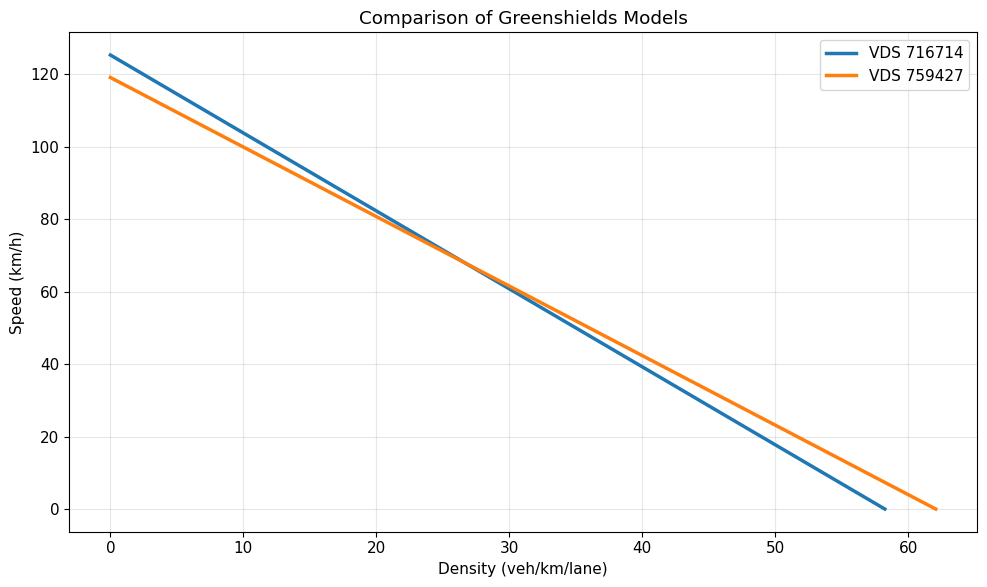

In [24]:
plt.figure(figsize=(10, 6))

for detector, df in cleaned.items():
    result = results[detector]

    k_fit = np.linspace(0, result["kj"], 300)

    v_fit = greenshields_model(k_fit, result["vf"], result["kj"])

    plt.plot(k_fit, v_fit, linewidth=2.5, label=f"VDS {detector}")

plt.xlabel("Density (veh/km/lane)")
plt.ylabel("Speed (km/h)")

plt.title("Comparison of Greenshields Models")

plt.legend()

plt.tight_layout()
plt.show()


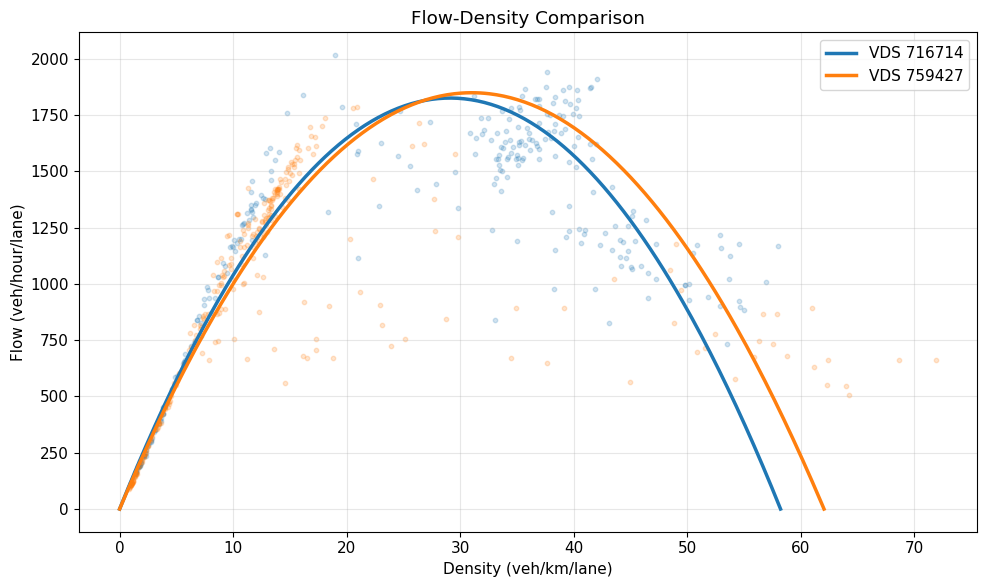

In [25]:
plt.figure(figsize=(10, 6))

for detector, df in cleaned.items():
    result = results[detector]

    k_fit = np.linspace(0, result["kj"], 300)

    q_fit = result["vf"] * k_fit * (1 - k_fit / result["kj"])

    plt.plot(k_fit, q_fit, linewidth=2.5, label=f"VDS {detector}")

    plt.scatter(df["density_per_lane"], df["flow_per_lane"], s=10, alpha=0.2)

plt.xlabel("Density (veh/km/lane)")
plt.ylabel("Flow (veh/hour/lane)")

plt.title("Flow-Density Comparison")

plt.legend()

plt.tight_layout()
plt.show()


In [26]:
# ==========================================
# Save processed datasets
# ==========================================

for detector, df in cleaned.items():
    output_file = output_dir / f"VDS_{detector}_processed.csv"

    df.to_csv(output_file, index=False)

    print(f"Saved: {output_file}")


# ==========================================
# Save Greenshields model parameters
# ==========================================

parameter_df = pd.DataFrame(
    [
        {
            "Detector": detector,
            **{
                key: value for key, value in result.items() if key not in ["covariance"]
            },
        }
        for detector, result in results.items()
    ]
)

parameter_file = output_dir / "greenshields_parameters.csv"

parameter_df.to_csv(parameter_file, index=False)

print(f"Saved: {parameter_file}")

print("\nAll results saved successfully.")

Saved: ..\..\data\processed\PeMS\VDS_716714_processed.csv
Saved: ..\..\data\processed\PeMS\VDS_759427_processed.csv
Saved: ..\..\data\processed\PeMS\greenshields_parameters.csv

All results saved successfully.
